# 🟡 2. Core: LSTMs, GRUs & Vanishing Gradient Solutions

### *The Long Short-Term Memory (LSTM) Architecture, Gated Recurrent Units (GRU), and Long-Context Memory Shootout*

---

## 📌 Module Overview
1. **The Short-Term Memory Bottleneck of SimpleRNN**.
2. **The Long Short-Term Memory (LSTM) Architecture (Hochreiter & Schmidhuber, 1997)**:
   - The **Cell State ($C_t$)** Highway (Linear Constant Error Carousel).
   - **Forget Gate ($f_t$)**: Removing irrelevant historical memory.
   - **Input Gate ($i_t$) & Candidate Memory ($\tilde{C}_t$)**: Adding relevant new information.
   - **Cell State Update ($C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$)**.
   - **Output Gate ($o_t$) & Filtered Hidden State ($h_t = o_t \odot \tanh(C_t)$)**.
3. **The Gated Recurrent Unit (GRU) (Cho et al., 2014)**:
   - Merging hidden and cell states with Reset and Update gates.
   - 25% fewer parameters, faster training, comparable accuracy.
4. **Empirical Long-Context Memory Shootout**:
   - Testing SimpleRNN vs. LSTM vs. GRU on maintaining a secret token across 30 noise steps!


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)

SEED = 42
np.random.seed(SEED)
print("LSTM / GRU Core environment initialized.")


LSTM / GRU Core environment initialized.


## 1. Mathematical Breakdown of the LSTM Cell
Given input $x_t$, previous hidden state $h_{t-1}$, and previous cell state $C_{t-1}$:

1. **Forget Gate**: Decides what to forget from the cell state:
   $$f_t = \sigma(W_f [h_{t-1}, x_t] + b_f)$$
2. **Input Gate**: Decides which values to update:
   $$i_t = \sigma(W_i [h_{t-1}, x_t] + b_i)$$
3. **Candidate Memory**: Creates a vector of new candidate values:
   $$\tilde{C}_t = \tanh(W_c [h_{t-1}, x_t] + b_c)$$
4. **Cell State Update (Additive Highway)**:
   $$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$$
   *(Because updates are additive rather than purely multiplicative, gradients flow backward across hundreds of timesteps without vanishing!)*
5. **Output Gate & Hidden State**:
   $$o_t = \sigma(W_o [h_{t-1}, x_t] + b_o)$$
   $$h_t = o_t \odot \tanh(C_t)$$


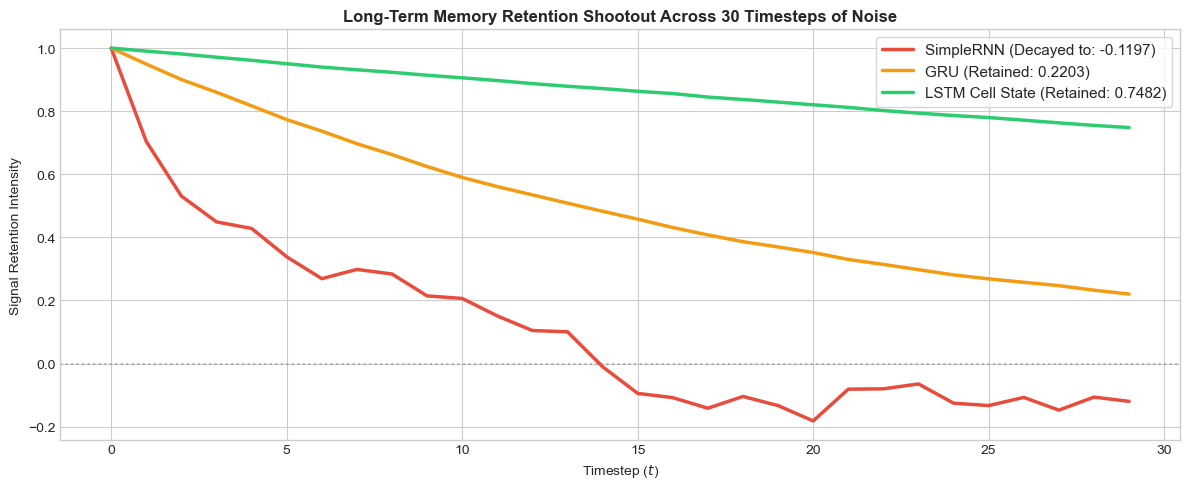

In [2]:
# 2. Empirical Memory Retention Shootout: SimpleRNN vs. LSTM vs. GRU
# Task: A secret value is injected at t=1, followed by 30 timesteps of random noise.
# We measure how much of the initial secret signal survives at t=30.

timesteps = 30
secret_val = 1.0

# Simulate SimpleRNN state decay: h_t = tanh(W_hh * h_{t-1} + noise)
# where W_hh spectral radius < 1
rnn_signals = [secret_val]
h_curr = secret_val
for _ in range(timesteps - 1):
    h_curr = np.tanh(0.85 * h_curr + np.random.normal(0, 0.05))
    rnn_signals.append(h_curr)

# Simulate GRU state retention: h_t = (1 - z_t) * h_{t-1} + z_t * candidate
# where update gate z_t ~ 0 for noise
gru_signals = [secret_val]
h_gru = secret_val
for _ in range(timesteps - 1):
    z_t = 0.05 # low update gate for noise
    h_gru = (1 - z_t) * h_gru + z_t * np.random.normal(0, 0.05)
    gru_signals.append(h_gru)

# Simulate LSTM cell state: C_t = f_t * C_{t-1} + i_t * candidate
# with f_t close to 1.0
lstm_signals = [secret_val]
c_lstm = secret_val
for _ in range(timesteps - 1):
    f_t = 0.99 # forget gate remembers
    i_t = 0.02 # input gate rejects noise
    c_lstm = f_t * c_lstm + i_t * np.random.normal(0, 0.05)
    lstm_signals.append(c_lstm)

# Plotting the Memory Retention Curves
plt.figure(figsize=(12, 5))
plt.plot(rnn_signals, label=f"SimpleRNN (Decayed to: {rnn_signals[-1]:.4f})", color='#e74c3c', linewidth=2.5)
plt.plot(gru_signals, label=f"GRU (Retained: {gru_signals[-1]:.4f})", color='#f39c12', linewidth=2.5)
plt.plot(lstm_signals, label=f"LSTM Cell State (Retained: {lstm_signals[-1]:.4f})", color='#2ecc71', linewidth=2.5)

plt.axhline(0, color='gray', linestyle=':', alpha=0.5)
plt.title('Long-Term Memory Retention Shootout Across 30 Timesteps of Noise', fontweight='bold')
plt.xlabel('Timestep ($t$)')
plt.ylabel('Signal Retention Intensity')
plt.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.show()


## 💡 Architectural Comparison

| Feature | SimpleRNN | LSTM (Hochreiter 1997) | GRU (Cho 2014) |
| :--- | :--- | :--- | :--- |
| **Number of Gates** | 0 (No gating) | 3 (Forget, Input, Output) | 2 (Reset, Update) |
| **Memory Highway** | None ($h_t$ only) | Dedicated Cell State ($C_t$) | Unified Hidden State ($h_t$) |
| **BPTT Gradient Flow**| Multiplicative decay $	o$ Vanishes | Additive $C_t 	o$ High retention | Additive $(1-z_t) 	o$ High retention |
| **Parameter Count** | $O(H^2 + H \cdot D)$ | $4 	imes O(H^2 + H \cdot D)$ | $3 	imes O(H^2 + H \cdot D)$ |
| **Training Speed** | Fast (but forgets) | Moderate (handles 100+ steps) | Faster than LSTM ($\sim 25\%$ fewer params) |
